# A primordial collapse

A one-zone free-fall collapse of primordial gas from 1 to 10^16 cm^-3
(the README's example): the density grows by 1% every 0.01 free-fall
times, and the chemistry and Tgas are solved over each step, as a hydro
code would call KROME. The physics is that of the shipped `collapse`
test: H2 cooling with its line opacity, the continuum cooling at high
density, the chemical heating and cooling, and the compression.

In [1]:
%matplotlib inline
import matplotlib
matplotlib.rcParams['figure.dpi'] = 90

In [2]:
# KROME-X: installed with pip, or this checkout (three folders up)
import sys, pathlib
try:
    import kromex
except ImportError:
    sys.path.insert(0, str(pathlib.Path.cwd().resolve().parents[2]))
    import kromex

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from kromex import Preprocessor

def build(name, cooling):
    kp = Preprocessor(network="primordial3")
    kp.thermal.cooling = cooling
    kp.thermal.heating = ["COMPRESS", "CHEM"]
    kp.thermal.h2_opacity = "RIPAMONTI"
    kp.thermal.gamma = "EXACT"
    kp.project.bindings = ["python"]
    kp.run(name)
    return kp.build()

net = build("build_collapse", ["H2", "CONT", "CHEM"])

wrote build_collapse/net_primordial3.hpp  (9 species, 27 reactions; split into 8 files; 19 runtime files copied, wrote Makefile + example.cpp + example.py)


In [4]:
def collapse(net, nH_end=1e16):
    n = net.densities({"H": 1.0, "H+": 1e-4, "e-": 1e-4, "H2": 1e-6,
                       "He": 0.0775})      # n_H = 1 cm^-3
    Tgas, nH = 100.0, 1.0
    opts = net.options(evolve_T=True)
    hist = []
    while nH < nH_end:
        tff = float(net.free_fall_time(n))     # the compression time [s]
        n, nH = n * 1.01, nH * 1.01            # the density grows 1% ...
        r = net.solve(n, Tgas, 0.01 * tff,     # ... in 0.01 tff
                      par={"tff": tff}, opts=opts)
        n, Tgas = r.n, float(r.Tgas)
        hist.append((nH, Tgas, n[net.idx("H2")] / nH, n[net.idx("e-")] / nH))
    return np.array(hist).T

import time
t0 = time.perf_counter()
nH, T, xH2, xe = collapse(net)
print("%d steps in %.2f s" % (len(nH), time.perf_counter() - t0))

3703 steps in 0.30 s


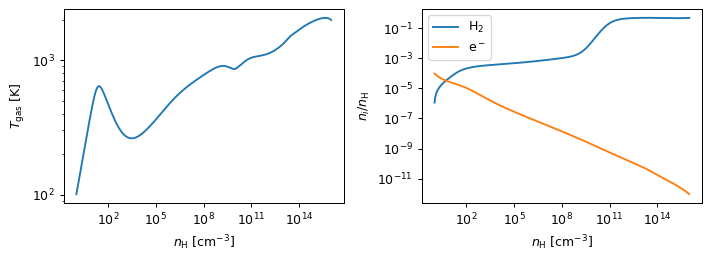

In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3))
a.loglog(nH, T)
a.set(xlabel=r"$n_\mathrm{H}$ [cm$^{-3}$]", ylabel=r"$T_\mathrm{gas}$ [K]")
b.loglog(nH, xH2, label=r"H$_2$")
b.loglog(nH, xe, label=r"e$^-$")
b.set(xlabel=r"$n_\mathrm{H}$ [cm$^{-3}$]", ylabel=r"$n_i / n_\mathrm{H}$")
b.legend()
fig.tight_layout()

Compression heats the gas to ~600 K, and H2 cooling brings it down to
~300 K around 10^3 cm^-3. The gas then warms as the H2 lines become
optically thick, and three-body H2 formation turns it fully molecular
around 10^10-10^11 cm^-3. Above 10^13 cm^-3 the continuum cooling keeps
the temperature near 2000 K.

## Changing the physics

The same collapse without the continuum (CIE) cooling: a second project,
generated with one option less.

wrote build_collapse_nocont/net_primordial3.hpp  (9 species, 27 reactions; split into 8 files; 19 runtime files copied, wrote Makefile + example.cpp + example.py)


Tgas at 1e16 cm^-3: 1986 K with CONT, 2412 K without


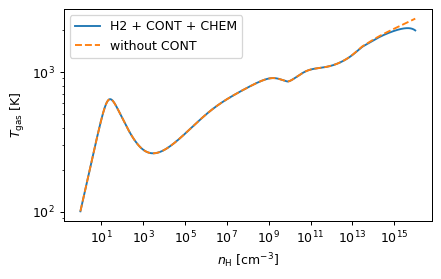

In [6]:
net2 = build("build_collapse_nocont", ["H2", "CHEM"])
nH2, T2, _, _ = collapse(net2)

fig, a = plt.subplots(figsize=(5, 3.2))
a.loglog(nH, T, label="H2 + CONT + CHEM")
a.loglog(nH2, T2, "--", label="without CONT")
a.set(xlabel=r"$n_\mathrm{H}$ [cm$^{-3}$]", ylabel=r"$T_\mathrm{gas}$ [K]")
a.legend()
fig.tight_layout()
print("Tgas at 1e16 cm^-3: %.0f K with CONT, %.0f K without" % (T[-1], T2[-1]))